In [84]:
import xarray as xr
#import rioxarray
import numpy as np
import matplotlib.pyplot as plt
import geopandas
from tqdm import tqdm
from shapely.geometry import box
import fiona
import rasterio
import rasterio.mask
import cartopy.crs as ccrs
import cartopy
import pandas as pd
import glob

In [85]:
Municipality_major_SA = geopandas.read_file('/cfs/klemming/projects/supr/chandra/data/Paper4/Data_previous_literature/SA_shape_AB2/AB0-1/SA_level1AB_Merge.shp')

In [86]:
final_df = geopandas.read_file('/cfs/klemming/projects/supr/chandra/data/Paper4/Output/Actor_dominance_HILDA+.shp')

In [87]:
final_df.rename(columns = {'ID':'ID1','Other area':'Other area (km2)', 'Crop area':'Crop area (km2)', 
                           'Pasture ar':'Pasture area (km2)', 'Forest are':'Forest area (km2)',
                           'Water area':'Water area (km2)', 'Cattle (pe':'Cattle (per km2)',
                           'Population':'Population_density (per km2)', 'Dominance-':'Dominance-Crop', 
                           'Dominanc_1':'Dominance-Pasture'}, inplace = True)

In [88]:
final_df

,Name,ID1,Area (km2),Crop area (km2),Pasture area (km2),Forest area (km2),Water area (km2),Other area (km2),Cattle (per km2),Population_density (per km2),...,loss_2013,loss_2014,loss_2015,loss_2016,loss_2017,loss_2018,loss_2019,loss_2020,loss_2021,geometry
0,Brazil_PR_Lupionópolis,0,120.842489,101.493964,0.000000,7.984040,6.845344,1.140196,10.067266,41.448277,...,0.002681,NaN,0.003227,0.003298,0.001613,0.000498,0.002097,0.000469,0.000505,"POLYGON Z ((-51.63021 -22.66372 0, -51.63011 -..."
1,Brazil_SP_Águas de Lindóia,1,55.477991,0.000000,28.561838,13.710402,0.000000,11.425280,12.652316,320.944061,...,0.070658,0.220704,0.030509,0.041351,0.135333,0.036443,0.087499,0.014176,0.056482,"POLYGON Z ((-46.61019 -22.43936 0, -46.60345 -..."
2,Brazil_PA_Uruará,2,10887.473237,19.745205,502.145292,9965.893356,0.000000,373.846853,13.362097,4.070190,...,41.684625,100.709755,90.302017,475.900150,100.887861,192.997515,161.545756,165.725568,147.356768,"POLYGON Z ((-53.85954 -2.8875 0, -53.85825 -2...."
3,Brazil_RS_São Leopoldo,3,104.054283,0.000000,3.220992,36.495553,0.000000,63.330272,1.712509,2308.399170,...,0.645918,0.494107,0.121827,0.107182,0.407883,0.373346,0.235608,0.440330,0.111416,"POLYGON Z ((-51.17861 -29.69309 0, -51.17045 -..."
4,Brazil_SP_Vargem,4,141.323371,12.529769,26.198815,88.849416,4.554584,5.694449,9.227102,83.034271,...,0.360531,0.337603,0.361523,0.684408,0.942206,0.436893,0.588376,0.354846,0.517292,"POLYGON Z ((-46.39678 -22.81069 0, -46.39477 -..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8659,Venezuela-Zulia-San Francisco,8659,140.033844,0.000000,2.430822,0.000000,0.000000,137.345553,5.863000,3961.173828,...,0.002618,0.016048,0.004729,0.000197,NaN,0.001059,0.000023,NaN,NaN,"POLYGON Z ((-71.75827 10.5302 0, -71.75822 10...."
8660,Venezuela-Zulia-Santa Rita,8660,501.148099,131.282609,21.877788,14.587026,4.861921,319.690975,14.034563,159.429108,...,1.264354,1.741946,1.336098,0.745189,1.371917,0.863023,0.419872,0.099175,0.121999,"MULTIPOLYGON Z (((-71.45708 10.47912 0, -71.45..."
8661,Venezuela-Zulia-Simón Bolívar,8661,310.323544,27.975635,64.473748,0.000000,4.866217,217.745956,13.100131,170.501465,...,0.434559,0.667971,0.105154,0.427800,0.531845,0.113439,0.090673,0.164373,0.218772,"POLYGON Z ((-71.36958 10.24261 0, -71.36958 10..."
8662,Venezuela-Zulia-Sucre,8662,742.398931,266.087682,21.977078,47.618412,3.661212,396.765536,17.066517,95.941711,...,0.263799,0.423747,0.254939,0.492236,1.073135,0.365784,0.196317,0.333588,0.126255,"MULTIPOLYGON Z (((-70.99045 9.19962 0, -70.989..."


In [89]:
final_df = final_df[['ID1','Population_density (per km2)', 'Cattle (per km2)']]

In [90]:
base_csv_1 = geopandas.read_file('/cfs/klemming/projects/supr/chandra/data/Paper4/Output/Base_shapefile_all_SA.shp')

In [91]:

# del base_csv_1['geometry']

In [92]:
Municipality = pd.concat([base_csv_1, final_df], axis=1)

del Municipality['ID1']

In [93]:
# Get CSV files list from a folder
path = '/cfs/klemming/projects/supr/chandra/data/Paper4/Data_previous_literature/Deforestation_data_gee'
csv_files = glob.glob(path + "/*.csv")

# Read each CSV file into DataFrame
# This creates a list of dataframes
df_list = (pd.read_csv(file) for file in csv_files)

# Concatenate all DataFrames
big_df   = pd.concat(df_list, ignore_index=True)
big_df = big_df.sort_values(by = 'ID')

big_df = big_df.reset_index()

big_df.rename(columns = {'ID': 'ID1'}, inplace = True)

Municipality = pd.concat([Municipality, big_df], axis=1)

In [94]:
# Get CSV files list from a folder
path = '/cfs/klemming/projects/supr/chandra/data/Paper4/Data_previous_literature/Mapbiomas/'
csv_files = glob.glob(path + "/*.csv")

# Read each CSV file into DataFrame
# This creates a list of dataframes
df_list = (pd.read_csv(file) for file in csv_files)

# Concatenate all DataFrames
big_df   = pd.concat(df_list, ignore_index=True)
big_df = big_df.sort_values(by = 'ID')

big_df = big_df.reset_index()

#big_df.rename(columns = {'ID': 'ID2'}, inplace = True)

#base_csv = pd.concat([base_csv, big_df], axis=1)

Municipality = pd.merge(Municipality, big_df[['ID', 'Area0', 'Area1', 'Area2', 'Area3', 'Area4', 'Area5', 'Area6']],#, 'AreaT']], 
         on="ID", how="left")

In [95]:
Municipality.rename(columns = {'Area0':'Classified (km2)', 'Area1': 'Forest area (km2)', 'Area2': 'Other area (km2)' , 'Area3': 'Crop area (km2)', 
                           'Area4': 'Pasture area (km2)', 'Area5': 'Water area (km2)', 'Area6': 'Unknown', 'AreaT': 'Area (km2)'}, inplace = True)

In [96]:
Municipality.columns

Index(['Name', 'ID', 'Area (km2)', 'geometry', 'Population_density (per km2)',
       'Cattle (per km2)', 'index', 'ID1', 'loss_2001', 'loss_2002',
       'loss_2003', 'loss_2004', 'loss_2005', 'loss_2006', 'loss_2007',
       'loss_2008', 'loss_2009', 'loss_2010', 'loss_2011', 'loss_2012',
       'loss_2013', 'loss_2014', 'loss_2015', 'loss_2016', 'loss_2017',
       'loss_2018', 'loss_2019', 'loss_2020', 'loss_2021', 'Classified (km2)',
       'Forest area (km2)', 'Other area (km2)', 'Crop area (km2)',
       'Pasture area (km2)', 'Water area (km2)', 'Unknown'],
      dtype='object')

In [155]:
def Landholders(Municipality_Brazil):
    global data
    a = []
    b = []
    c = []
    Population_density_per_unit_area_croplands = Municipality_Brazil['Population_density (per km2)']*Municipality_Brazil['Area (km2)']/Municipality_Brazil['Crop area (km2)']
    Cattles_per_unit_area_pasture = Municipality_Brazil['Cattle (per km2)']/(Municipality_Brazil['Pasture area (km2)']/Municipality_Brazil['Area (km2)'])
    for i in tqdm(range(Municipality_Brazil.shape[0])):
        a.append('Blank')
        b.append('Blank')
        c.append('Blank')
        
    ##### Crop analysis            
    for i in tqdm(range(Municipality_Brazil.shape[0])):
        data = Municipality_Brazil.iloc[i]
        if data['Crop area (km2)'] == 0:
            a[i] = np.nan
            continue
        if data['Crop area (km2)'] <= 1:
            a[i] = 'Crop-Small'
            continue
        if (data['Crop area (km2)']  > 1) & (data['Crop area (km2)'] <=25):
            a[i] = 'Crop-Medium'
            continue
        if (data['Crop area (km2)']  > 25):
            a[i] = 'Crop-Large'
            continue
        else:
            a[i] = 'Crop (Check)'  

    for i in tqdm(range(Municipality_Brazil.shape[0])):
        data = Municipality_Brazil.iloc[i]
        if (Population_density_per_unit_area_croplands[i] > 100) & (a[i] == 'Crop-Large'):
            a[i] = 'Crop-Small'
            continue
    
    for i in tqdm(range(Municipality_Brazil.shape[0])):
        data = Municipality_Brazil.iloc[i]
        if (data['Forest area (km2)']/ data['Area (km2)'] > 0.90):
            a[i] = 'Remote'
    
    
    ##### Pasture analysis            
    for i in tqdm(range(Municipality_Brazil.shape[0])):
        data = Municipality_Brazil.iloc[i]
        if data['Pasture area (km2)'] == 0:
            b[i] = np.nan
            continue
        if (Cattles_per_unit_area_pasture[i] == np.nan) | (Cattles_per_unit_area_pasture[i] == np.inf):
            b[i] = np.nan
            continue
        if (Cattles_per_unit_area_pasture[i] > 30) | (data['Cattle (per km2)']  > 15):
            b[i] = 'Pasture-Large'
            continue
        if Cattles_per_unit_area_pasture[i] <= 10:
            b[i] = 'Pasture-Small'
            continue
        if (Cattles_per_unit_area_pasture[i] > 10) & (Cattles_per_unit_area_pasture[i] <=30):
            b[i] = 'Pasture-Medium'
            continue
        else:
            b[i] = 'Pasture (Check)'
            
    for i in tqdm(range(Municipality_Brazil.shape[0])):
        data = Municipality_Brazil.iloc[i]
        if (data['Forest area (km2)']/ data['Area (km2)'] > 0.90):
            b[i] = 'Remote'
            continue
        if (data['Other area (km2)']/ data['Area (km2)'] > 0.70):
            b[i] = 'Remote (Other)'
    
    
    for i in tqdm(range(Municipality_Brazil.shape[0])):
        """
        if b[i] == 'Remote (Other)':
            c[i] = 'Remote (Other)'
            continue
        """
        if (a[i] == 'Remote (Other)') & (b[i] == 'Crop-Small'):
            c[i] = ' Small'
            continue
        if (a[i] == 'Crop-Small') & (b[i] == 'Remote (Other)'):
            c[i] = ' Small'
            continue
        if (a[i] == 'Remote (Other)') & (b[i] == 'Crop-Medium'):
            c[i] = ' Medium'
            continue
        if (a[i] == 'Crop-Medium') & (b[i] == 'Remote (Other)'):
            c[i] = ' Medium'
            continue
        if (a[i] == 'Remote (Other)') & (b[i] == 'Crop-Large'):
            c[i] = ' Large'
            continue
        if (a[i] == 'Crop-Large') & (b[i] == 'Remote (Other)'):
            c[i] = ' Large'
            continue
        if (a[i] == 'Remote') & (b[i] == 'Remote'):
            c[i] = 'Remote (Forest)'
            continue
        if (a[i] == 'Crop-Small') & (b[i] == 'Pasture-Small'):
            c[i] = ' Small'
            continue
        if ((a[i] == 'Remote') & (b[i] == 'Pasture-Small') | (a[i] == 'Crop-Small') & (b[i] == 'Remote')):
            c[i] = ' Small'
            continue
        if ((a[i] == 'Crop-Small') & pd.isna(b[i])) | (pd.isna(a[i]) & (b[i] == 'Pasture-Small')):
            c[i] = ' Small'
            continue
        if (a[i] == 'Crop-Medium') & (b[i] == 'Pasture-Medium'):
            c[i] = ' Medium'
            continue
        if ((a[i] == 'Remote') & (b[i] == 'Pasture-Medium') | (a[i] == 'Crop-Medium') & (b[i] == 'Remote')):
            c[i] = ' Medium'
            continue
        if ((a[i] == 'Crop-Medium') & pd.isna(b[i])) | (pd.isna(a[i]) & (b[i] == 'Pasture-Medium')):
            c[i] = ' Medium'
            continue
        if (a[i] == 'Crop-Large') & (b[i] == 'Pasture-Large'):
            c[i] = ' Large'
            continue
        if ((a[i] == 'Remote') & (b[i] == 'Pasture-Large') | (a[i] == 'Crop-Large') & (b[i] == 'Remote')):
            c[i] = ' Large'
            continue
        if ((a[i] == 'Crop-Large') & pd.isna(b[i])) | (pd.isna(a[i]) & (b[i] == 'Pasture-Large')):
            c[i] = ' Large'
            continue
        if (pd.isna(b[i]) & pd.isna(a[i])):
            c[i] = 'Remote (Other)'
            continue
        if (pd.isna(a[i])) & (b[i] == 'Remote (Other)'):
            c[i] = 'Remote (Other)'
        else:
            c[i] = 'Check'
        
    for i in tqdm(range(Municipality_Brazil.shape[0])):
        data = Municipality_Brazil.iloc[i]
    
        if c[i] == 'Check':
    
            crop_fraction = data['Crop area (km2)'] / data['Area (km2)']
            pasture_fraction = data['Pasture area (km2)'] / data['Area (km2)']
    
            if crop_fraction >= pasture_fraction:
    
                if isinstance(a[i], str) and a[i].startswith('Crop-'):
                    c[i] = ' ' + a[i].split('-', 1)[1]
    
                elif a[i] == 'Remote':
                    c[i] = 'Remote (Forest)'
    
                else:
                    print(
                        "Unhandled crop case:",
                        "i =", i,
                        "a =", a[i],
                        "b =", b[i],
                        "crop_fraction =", crop_fraction,
                        "pasture_fraction =", pasture_fraction
                    )
                    c[i] = 'Check-2'
    
            else:
    
                if isinstance(b[i], str) and b[i].startswith('Pasture-'):
                    c[i] = ' ' + b[i].split('-', 1)[1]
    
                elif b[i] == 'Remote':
                    c[i] = 'Remote (Forest)'
    
                elif b[i] == 'Remote (Other)':
                    c[i] = 'Remote (Other)'
    
                else:
                    print(
                        "Unhandled pasture case:",
                        "i =", i,
                        "a =", a[i],
                        "b =", b[i],
                        "crop_fraction =", crop_fraction,
                        "pasture_fraction =", pasture_fraction
                    )
                    c[i] = 'Check-2'
    return a,b,c

In [98]:
Municipality['Landuse Cover'] = (Municipality['Classified (km2)']/Municipality['Area (km2)'])

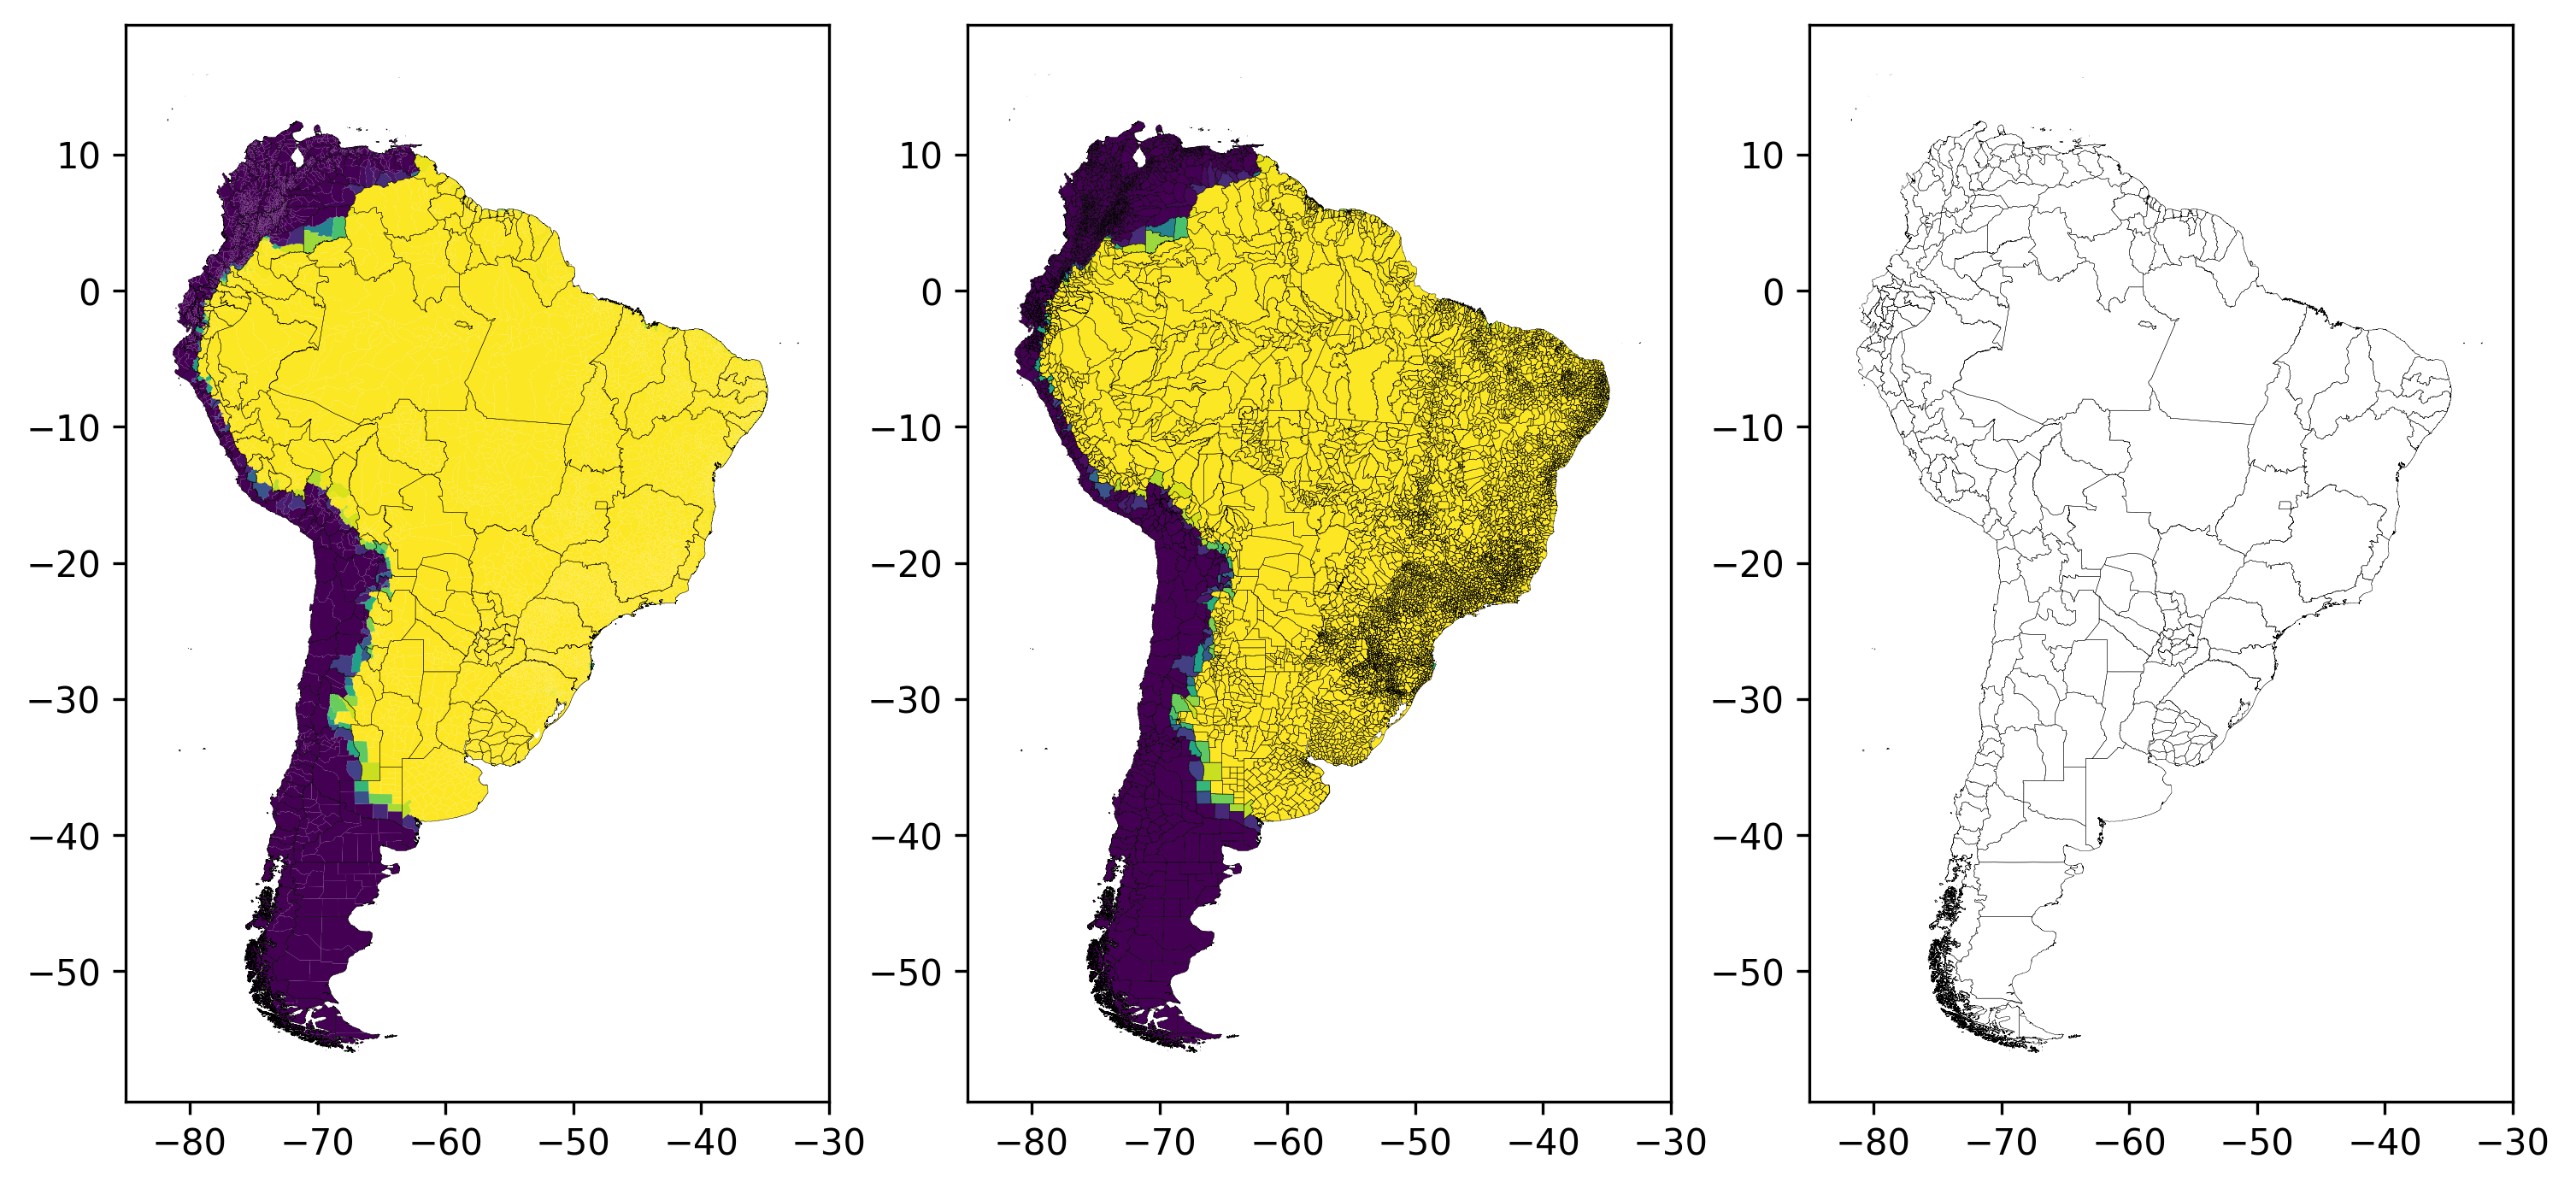

In [99]:
fig, ax = plt.subplots(1,3, figsize=(10,18), dpi = 300)

Municipality.plot(column = 'Landuse Cover', ax = ax[0])
Municipality.plot(column = 'Landuse Cover', ax = ax[1])


Municipality_major_SA.plot(column = 'NAME_1', edgecolor = 'k', facecolor = 'None', ax = ax[0], lw = 0.1)
Municipality.plot(column = 'Name', edgecolor = 'k', facecolor = 'None', ax = ax[1], lw = 0.1)
Municipality_major_SA.plot(column = 'NAME_1', edgecolor = 'k', facecolor = 'None', ax = ax[2], lw = 0.1)

for i in range(3):
    ax[i].set_xlim(-85, -30)
plt.tight_layout()

In [100]:
Municipality = Municipality[Municipality['Landuse Cover'] >= 0.9]  

Municipality = Municipality.reset_index()

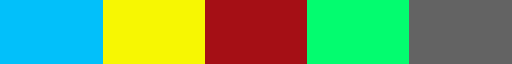

In [101]:
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
cmap = ListedColormap(["#a50f15",'#f7f702','#02c0fa','#03fc6f'])
cmap

cmap2 = ListedColormap(["#a50f15",'#f7f702','#02c0fa','#03fc6f', '#636363'])
cmap2

cmap3 = ListedColormap(['#02c0fa','#f7f702',"#a50f15",'#03fc6f', '#636363'])
cmap3

In [156]:
Municipality['Dominance-crop'], Municipality['Dominance-pasture'], Municipality['Dominance'] = Landholders(Municipality)

Municipality['Dominance'] = Municipality['Dominance'].replace(to_replace=' Small', value = 1)
Municipality['Dominance'] = Municipality['Dominance'].replace(to_replace=' Medium', value = 2)
Municipality['Dominance'] = Municipality['Dominance'].replace(to_replace=' Large', value = 3)
Municipality['Dominance'] = Municipality['Dominance'].replace(to_replace='Remote (Forest)', value = 4)
Municipality['Dominance'] = Municipality['Dominance'].replace(to_replace='Remote (Other)', value = 5)


100%|████████████████████████████████████████████████████████████████████████████| 6874/6874 [00:00<00:00, 21991.51it/s]
/tmp/ipykernel_54147/974511180.py:7: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  Municipality['Dominance'] = Municipality['Dominance'].replace(to_replace='Remote (Other)', value = 5)


In [103]:
type(Municipality)

geopandas.geodataframe.GeoDataFrame

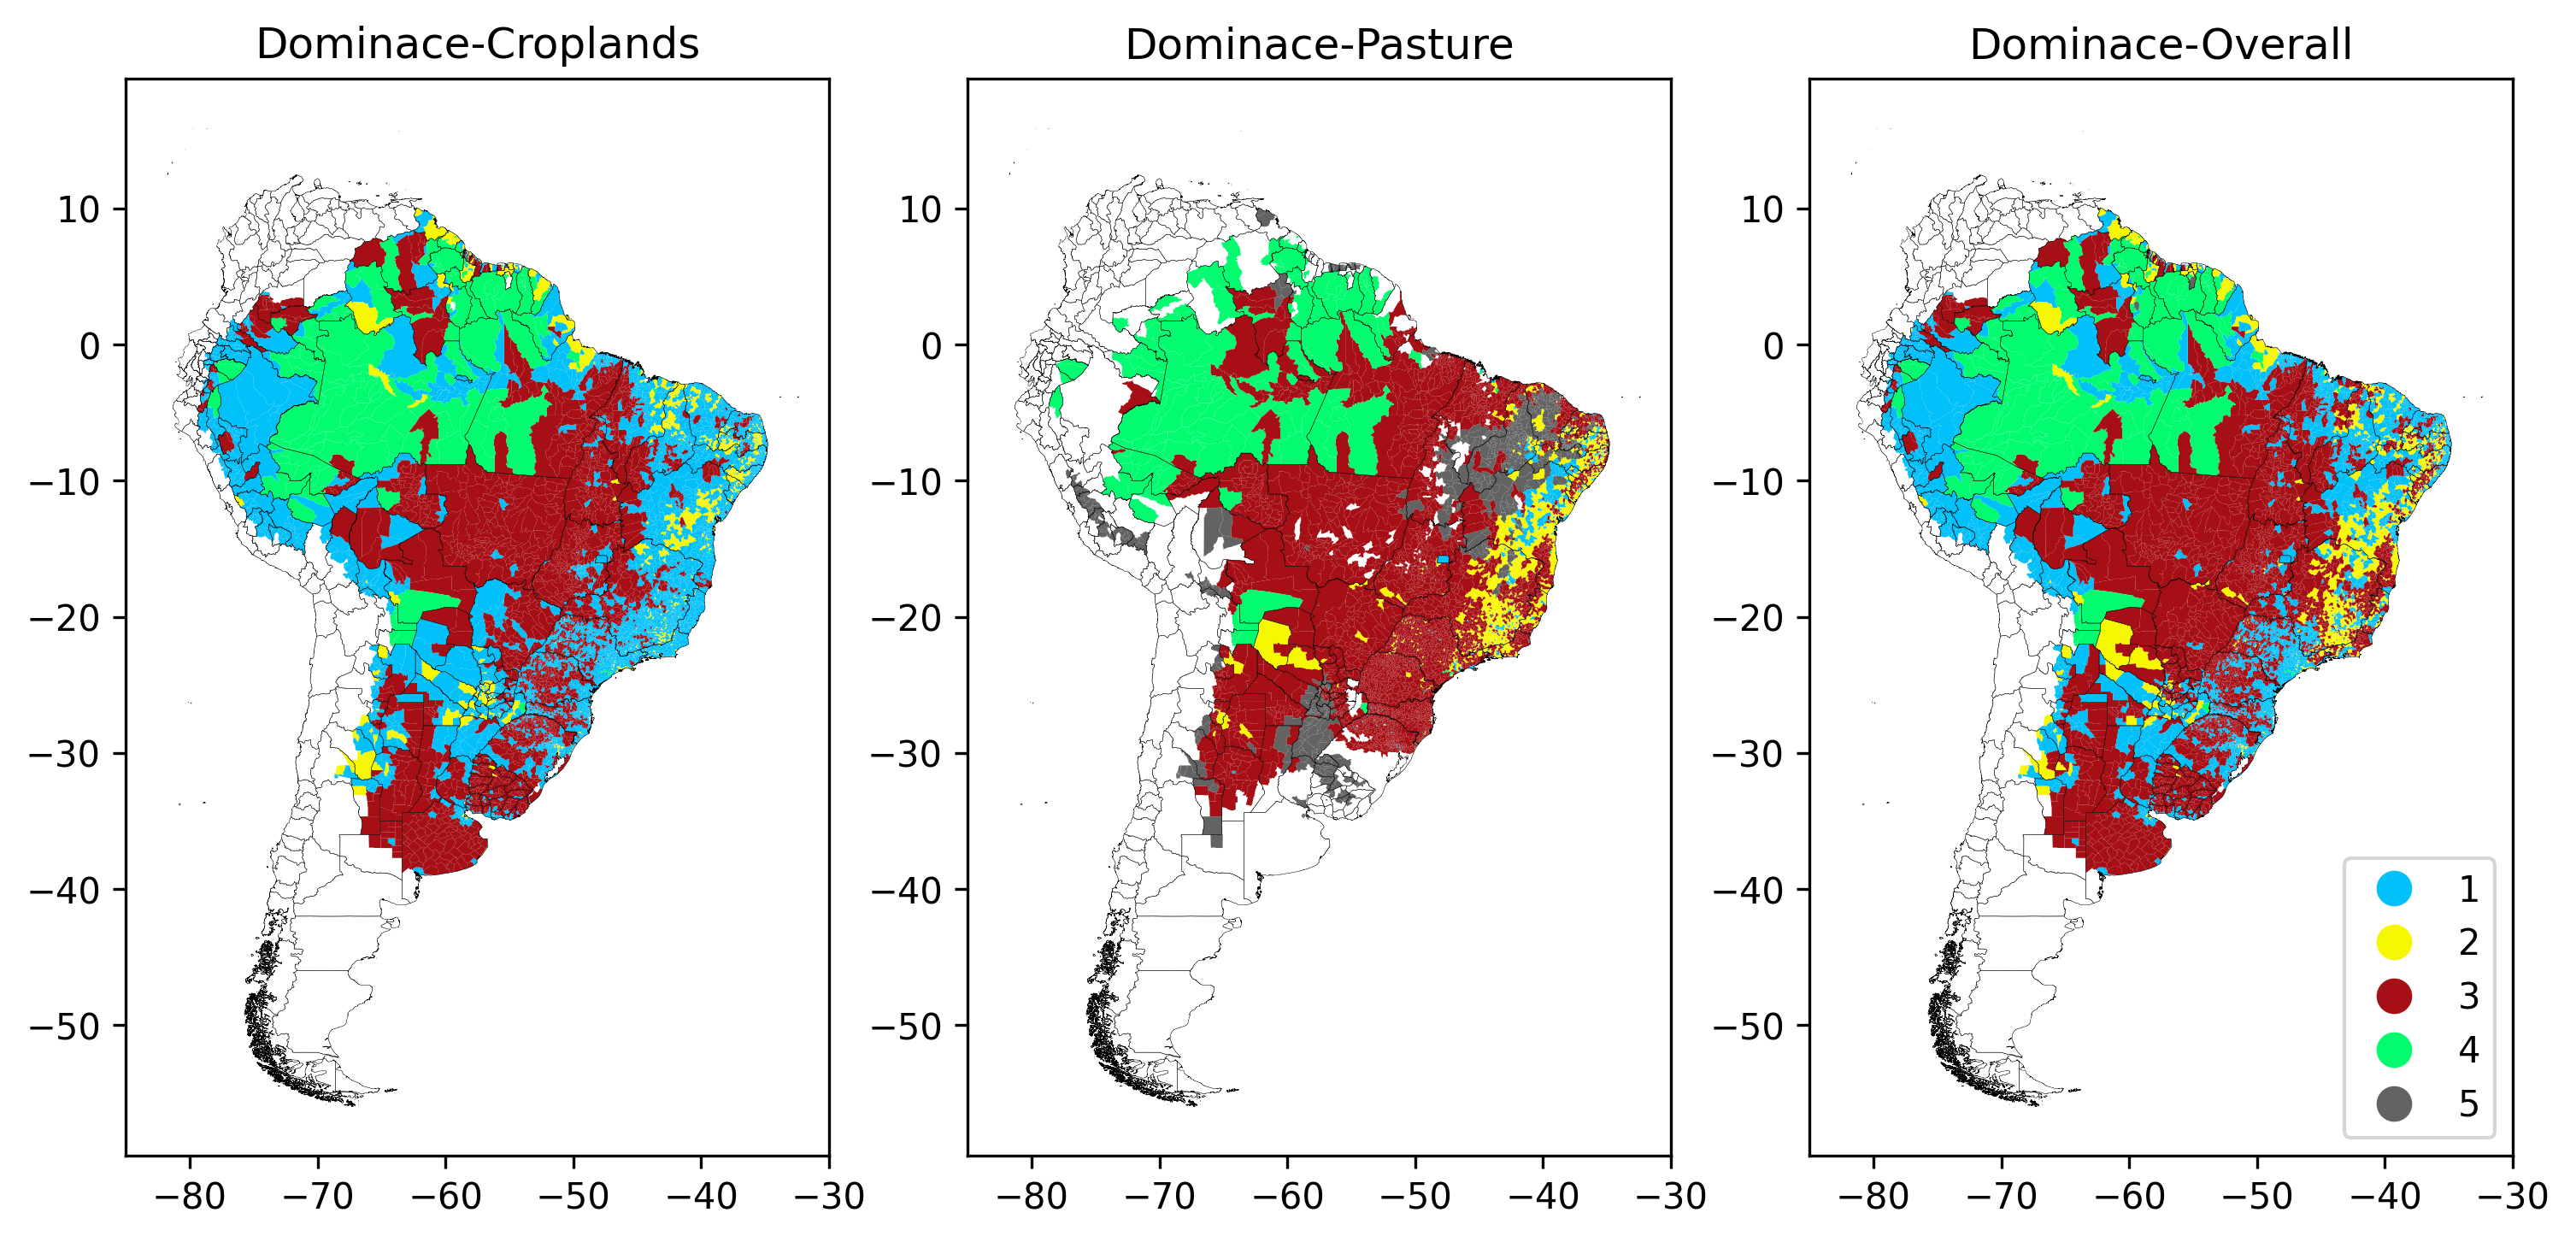

In [154]:
fig, ax = plt.subplots(1,3, figsize=(10,18), dpi = 300)

Municipality.plot(column = 'Dominance-crop', legend = False, cmap = cmap, ax = ax[0])
Municipality.plot(column = 'Dominance-pasture', legend = False, cmap = cmap2, ax = ax[1])
Municipality.plot(column = 'Dominance', legend = True, cmap = cmap3, ax = ax[2], categorical=True, legend_kwds={'loc': 'lower right'})
#ax[2].legend(['Smallholders', 'Medium landholders', 'Large landholders', 'Remote (Forest)', 'Remote (Others)'])

ax[0].set_title('Dominace-Croplands')
ax[1].set_title('Dominace-Pasture')
ax[2].set_title('Dominace-Overall')

Municipality_major_SA.plot(column = 'NAME_1', edgecolor = 'k', facecolor = 'None', ax = ax[0], lw = 0.1)
Municipality_major_SA.plot(column = 'NAME_1', edgecolor = 'k', facecolor = 'None', ax = ax[1], lw = 0.1)
Municipality_major_SA.plot(column = 'NAME_1', edgecolor = 'k', facecolor = 'None', ax = ax[2], lw = 0.1)

for i in range(3):
    ax[i].set_xlim(-85, -30)
plt.tight_layout()

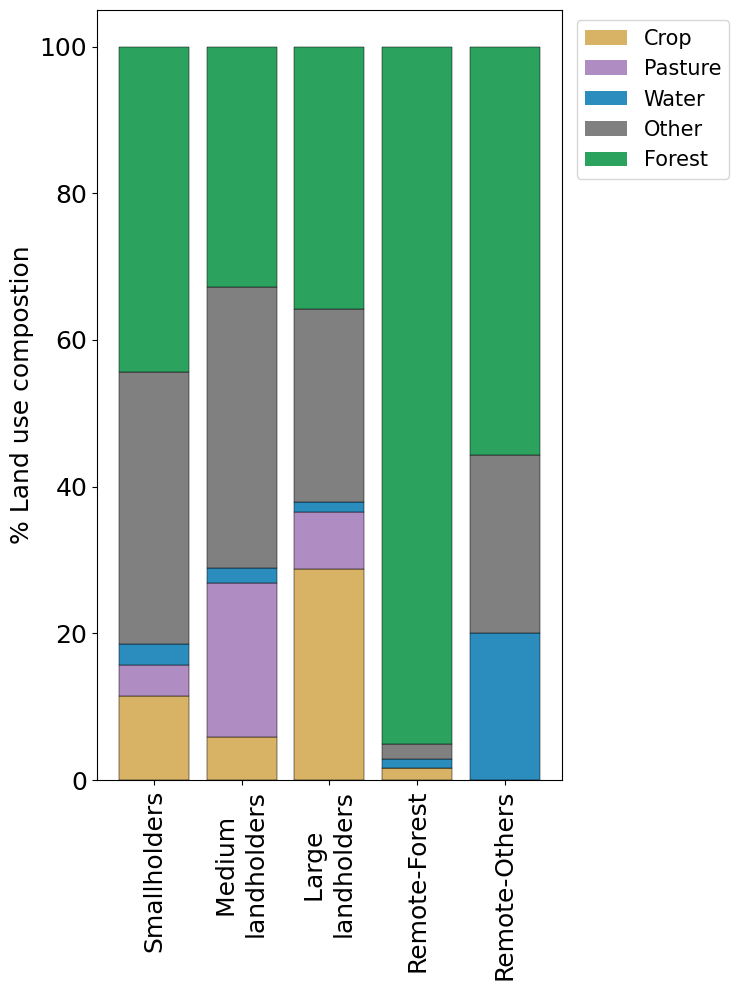

In [157]:
fig = plt.figure(figsize=(6, 10))
ax = fig.add_subplot(111)
# create data
x = [1,2,3,4,5]
array = {}
color = ['#d8b365','#af8dc3','#2b8cbe', 'grey', '#2ca25f']
landuse = [ "Crop", "Pasture", "Water", "Other", "Forest"]
for dominance in x:
    a = []
    for j in landuse:
        a.append(Municipality[j+' area (km2)'].where(Municipality['Dominance'] == dominance).sum())
    array[dominance] = np.array(a)
    array[dominance] = array[dominance]/(array[dominance].sum())*100 #remove this line for aboslute values
array = pd.DataFrame([array[x[0]], array[x[1]], array[x[2]], array[x[3]], array[x[4]]], columns=[landuse])
  
# plot bars in stack manner
array.plot(y = landuse, kind='bar', stacked=True, ax = ax, 
           legend = False, color = color, width = 0.8, edgecolor = 'black', lw = 0.35)
ax.set_ylabel('% Land use compostion', fontsize = 18)
ax.set_xticklabels(['Smallholders','Medium \nlandholders','Large \nlandholders','Remote-Forest', 'Remote-Others'])
ax.tick_params(axis='both', which='major', labelsize=18)
ax.tick_params(axis='x', labelrotation=90)
#ax.set_ylim(0,100)
## Plotting ecoregion legend
#Ecozone_unique_name = [ "Crop", "Pasture", "Water", "Other", "Forest"]

import matplotlib.patches as mpatches
from matplotlib.font_manager import FontProperties

recs = []
for i in range(0,len(color)):
    recs.append(mpatches.Rectangle((0,0),1,1,fc=(color)[i]))
fontP = FontProperties()
fontP.set_size('15')
plt.legend(recs,landuse, ncol = 1,prop=fontP, bbox_to_anchor=(1.01, 1))

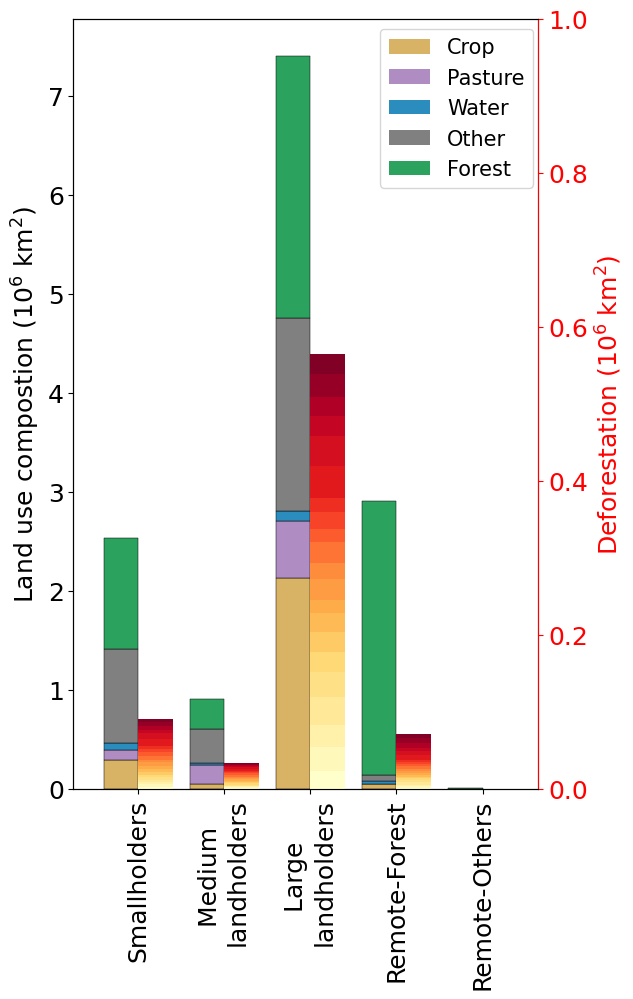

In [158]:
fig = plt.figure(figsize=(6, 10))
ax = fig.add_subplot(111)
ax2 = ax.twinx()
# create data
x = [1,2,3,4,5]
array = {}
color = ['#d8b365','#af8dc3', '#2b8cbe', 'grey', '#2ca25f']
landuse = [ "Crop", "Pasture", "Water", "Other", "Forest"]
for dominance in x:
    a = []
    for j in landuse:
        a.append(Municipality[j+' area (km2)'].where(Municipality['Dominance'] == dominance).sum())
    array[dominance] = np.array(a)
    #array[dominance] = array[dominance]/(array[dominance].sum())*100 #remove this line for aboslute values
array = pd.DataFrame([array[x[0]], array[x[1]], array[x[2]], array[x[3]], array[x[4]]], columns=[landuse])
array = array/1000000
# plot bars in stack manner
array.plot(y = landuse, kind='bar', stacked=True, ax = ax, 
           legend = False, color = color, align='edge',width = -0.4, edgecolor = 'black', lw = 0.35)
ax.set_ylabel(r'Land use compostion (10$^{6}$ km${^2}$)', fontsize = 18)
ax.set_xticklabels(['Smallholders','Medium \nlandholders','Large \nlandholders','Remote-Forest', 'Remote-Others'])
ax.tick_params(axis='both', which='major', labelsize=18)
ax.tick_params(axis='x', labelrotation=90)


import matplotlib.patches as mpatches
from matplotlib.font_manager import FontProperties
recs = []
for i in range(0,len(color)):
    recs.append(mpatches.Rectangle((0,0),2,2,fc=(color)[i]))
fontP = FontProperties()
fontP.set_size('15')
ax.legend(recs,landuse, ncol = 1,prop=fontP, bbox_to_anchor=(1.01, 1))

# create data
array_1 = {}
landuse = np.arange(2001,2022,1)
landuse = list(map(str, landuse))
k = 0 ## connects to total sum array
for dominance in x:
    a = []
    for j in landuse:
        a.append(Municipality['loss_'+str(j)].where(Municipality['Dominance'] == dominance).sum())
    array_1[dominance] = np.array(a)
    #array_1[dominance] = array_1[dominance]/array.iloc[k].sum()*100 #remove this line for aboslute values
    k = k+1
array_1 = pd.DataFrame([array_1[x[0]], array_1[x[1]], array_1[x[2]], array_1[x[3]], array_1[x[4]]], columns=[landuse])
array_1 = array_1/1000000
# plot bars in stack manner
array_1.plot(y = landuse, kind='bar', stacked=True, ax = ax2, 
           legend = False, cmap = 'YlOrRd', align='edge',width = 0.4)
ax2.set_ylabel('Deforestation (10$^{6}$ km${^2}$)', fontsize = 18)
ax2.set_xticklabels(['Smallholders','Medium \nlandholders','Large \nlandholders','Remote-Forest', 'Remote-Others'])
ax2.tick_params(axis='both', which='major', labelsize=18)
ax2.tick_params(axis='x', labelrotation=90)
ax2.set_xlim(-0.75,)
ax2.set_ylim(0,1)
ax2.yaxis.label.set_color('red')
ax2.spines["right"].set_edgecolor('red')
ax2.tick_params(axis='y', colors='red')

In [171]:
Municipality.to_file('/home/chandra/data/Paper4/Output/Actor_dominance_Mapbiomas.shp', mode="w")

/tmp/ipykernel_3472379/2784108880.py:1: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  Municipality.to_file('/home/chandra/data/Paper4/Output/Actor_dominance_Mapbiomas.shp', mode="w")


In [2]:
Municipality = geopandas.read_file('/home/chandra/data/Paper4/Output/Actor_dominance_Mapbiomas.shp')

In [3]:
Municipality = Municipality.rename(columns = {'Crop area':'Crop area (km2)', 
                           'Pasture ar':'Pasture area (km2)', 'Forest are':'Forest area (km2)',
                           'Water area':'Water area (km2)', 'Cattle (pe':'Cattle (per km2)',
                           'Population':'Population_density (per km2)', 'Dominance-':'Dominance-Crop', 
                           'Dominanc_1':'Dominance-Pasture', 'Landuse Co':'Landuse Cover', 'Other area': 'Non forest area (km2)'})

In [4]:
Municipality.columns

Index(['level_0', 'Name', 'ID', 'Area (km2)', 'Population_density (per km2)',
       'Cattle (per km2)', 'index', 'ID1', 'loss_2001', 'loss_2002',
       'loss_2003', 'loss_2004', 'loss_2005', 'loss_2006', 'loss_2007',
       'loss_2008', 'loss_2009', 'loss_2010', 'loss_2011', 'loss_2012',
       'loss_2013', 'loss_2014', 'loss_2015', 'loss_2016', 'loss_2017',
       'loss_2018', 'loss_2019', 'loss_2020', 'loss_2021', 'Classified',
       'Forest area (km2)', 'Non forest area (km2)', 'Crop area (km2)',
       'Pasture area (km2)', 'Water area (km2)', 'Unknown', 'Landuse Cover',
       'Dominance-Crop', 'Dominance-Pasture', 'Dominance', 'geometry'],
      dtype='object')

In [5]:
Municipality['Other area (km2)'] = Municipality['Unknown']+Municipality['Water area (km2)']

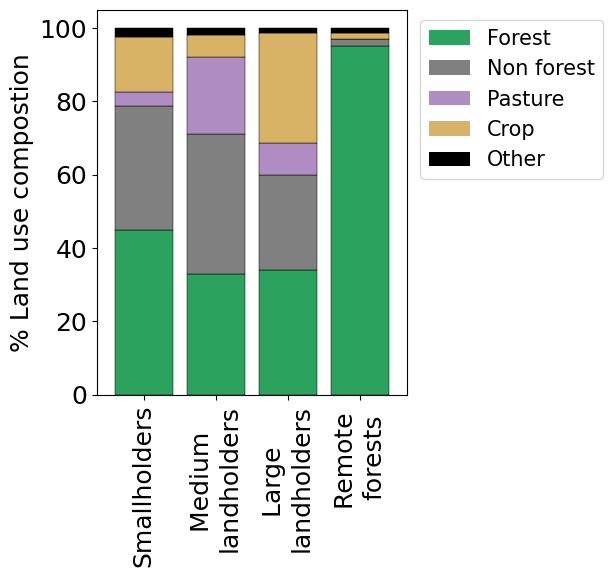

In [7]:
fig = plt.figure(figsize=(4, 5))
ax = fig.add_subplot(111)
# create data
x = [1,2,3,4,5]
array = {}
color = ['black','#d8b365','#af8dc3', 'grey', '#2ca25f'][::-1]
landuse = ["Other","Crop", "Pasture", "Non forest", "Forest"][::-1]
for dominance in x:
    a = []
    for j in landuse:
        a.append(Municipality[j+' area (km2)'].where(Municipality['Dominance'] == dominance).sum())
    array[dominance] = np.array(a)
    array[dominance] = array[dominance]/(array[dominance].sum())*100 #remove this line for aboslute values
array = pd.DataFrame([array[x[0]], array[x[1]], array[x[2]], array[x[3]]], columns=[landuse])
  
# plot bars in stack manner
array.plot(y = landuse, kind='bar', stacked=True, ax = ax, 
           legend = False, color = color, width = 0.8, edgecolor = 'black', lw = 0.35)
ax.set_ylabel('% Land use compostion', fontsize = 18)
ax.set_xticklabels(['Smallholders','Medium \nlandholders','Large \nlandholders','Remote \nforests'])
ax.tick_params(axis='both', which='major', labelsize=18)
ax.tick_params(axis='x', labelrotation=90)
#ax.set_ylim(0,100)
## Plotting ecoregion legend
#Ecozone_unique_name = [ "Crop", "Pasture", "Water", "Other", "Forest"]

import matplotlib.patches as mpatches
from matplotlib.font_manager import FontProperties

recs = []
for i in range(0,len(color)):
    recs.append(mpatches.Rectangle((0,0),1,1,fc=(color)[i]))
fontP = FontProperties()
fontP.set_size('15')
plt.legend(recs,landuse, ncol = 1,prop=fontP, bbox_to_anchor=(1.01, 1))

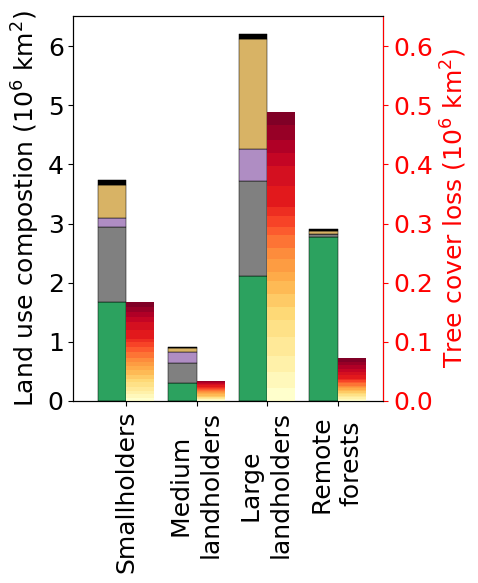

In [9]:
fig = plt.figure(figsize=(4, 5))
ax = fig.add_subplot(111)
ax2 = ax.twinx()
# create data
x = [1,2,3,4,5]
array = {}
color = ['black','#d8b365','#af8dc3', 'grey', '#2ca25f'][::-1]
landuse = ["Other","Crop", "Pasture", "Non forest", "Forest"][::-1]
for dominance in x:
    a = []
    for j in landuse:
        a.append(Municipality[j+' area (km2)'].where(Municipality['Dominance'] == dominance).sum())
    array[dominance] = np.array(a)
    #array[dominance] = array[dominance]/(array[dominance].sum())*100 #remove this line for aboslute values
array = pd.DataFrame([array[x[0]], array[x[1]], array[x[2]], array[x[3]]], columns=[landuse])
array = array/1000000
# plot bars in stack manner
array.plot(y = landuse, kind='bar', stacked=True, ax = ax, 
           legend = False, color = color, align='edge',width = -0.4, edgecolor = 'black', lw = 0.35)
ax.set_ylabel(r'Land use compostion (10$^{6}$ km${^2}$)', fontsize = 18)
ax.set_xticklabels(['Smallholders','Medium \nlandholders','Large \nlandholders','Remote \nforests'])
ax.tick_params(axis='both', which='major', labelsize=18)
ax.tick_params(axis='x', labelrotation=90)


import matplotlib.patches as mpatches
from matplotlib.font_manager import FontProperties
recs = []
for i in range(0,len(color)):
    recs.append(mpatches.Rectangle((0,0),2,2,fc=(color)[i]))
fontP = FontProperties()
fontP.set_size('15')
#ax.legend(recs,landuse, ncol = 1,prop=fontP, bbox_to_anchor=(0.51, 1), frameon=False)

# create data
array_1 = {}
landuse = np.arange(2001,2022,1)
landuse = list(map(str, landuse))
k = 0 ## connects to total sum array
for dominance in x:
    a = []
    for j in landuse:
        a.append(Municipality['loss_'+str(j)].where(Municipality['Dominance'] == dominance).sum())
    array_1[dominance] = np.array(a)
    #array_1[dominance] = array_1[dominance]/array.iloc[k].sum()*100 #remove this line for aboslute values
    k = k+1
array_1 = pd.DataFrame([array_1[x[0]], array_1[x[1]], array_1[x[2]], array_1[x[3]]], columns=[landuse])
array_1 = array_1/1000000
# plot bars in stack manner
array_1.plot(y = landuse, kind='bar', stacked=True, ax = ax2, 
           legend = False, cmap = 'YlOrRd', align='edge',width = 0.4)
ax2.set_ylabel('Tree cover loss (10$^{6}$ km${^2}$)', fontsize = 18)
ax2.set_xticklabels(['Smallholders','Medium \nlandholders','Large \nlandholders','Remote \nforests'])
ax2.tick_params(axis='both', which='major', labelsize=18)
ax2.tick_params(axis='x', labelrotation=90)
ax2.set_xlim(-0.75,)
ax2.set_ylim(0,ax.get_ylim()[1]/10)
ax2.yaxis.label.set_color('red')
ax2.spines["right"].set_edgecolor('red')
ax2.tick_params(axis='y', colors='red')

In [159]:
array['Sum'] = array.sum(axis = 1)
array

,Crop,Pasture,Water,Other,Forest,Sum
0,0.290139,0.106277,0.072158,0.943018,1.126173,2.537765
1,0.052385,0.190426,0.017863,0.346228,0.296609,0.903511
2,2.127696,0.578863,0.099549,1.946641,2.654096,7.406845
3,0.047675,0.000782,0.035417,0.059674,2.769200,2.912749
4,0.000000,0.000000,0.001426,0.001730,0.003976,0.007132


In [160]:
array['Sum']

,Sum
0,2.537765
1,0.903511
2,7.406845
3,2.912749
4,0.007132


In [12]:
array['Sum'] = array.sum(axis = 1)
array

,Forest,Non forest,Pasture,Crop,Other,Sum
0,1.676165,1.266618,0.149205,0.553869,0.093913,3.739770
1,0.296609,0.346228,0.190426,0.052385,0.017867,0.903514
2,2.104104,1.623041,0.535935,1.863966,0.077961,6.205007
3,2.769200,0.059674,0.000782,0.047675,0.035418,2.912750


In [18]:
array['Sum']

,Sum
0,3.739770
1,0.903514
2,6.205007
3,2.912750


In [19]:
array_1.sum(axis = 1)

0    0.167132
1    0.033969
2    0.488921
3    0.071814
dtype: float64

In [22]:
print(0.167132/(0.149205+0.553869)*100, 0.033969/(0.190426+0.052385)*100, 0.488921/(0.535935+1.863966)*100, 0.071814/(2.912750)*100)

23.77160867846059 13.989893373858681 20.37254870096725 2.4655051068577807


In [20]:
array/13.761042*100

,Forest,Non forest,Pasture,Crop,Other,Sum
0,12.180511,9.204373,1.084255,4.024908,0.682459,27.176506
1,2.155423,2.516001,1.383804,0.380675,0.129837,6.565740
2,15.290299,11.794461,3.894584,13.545237,0.566537,45.091117
3,20.123477,0.433646,0.005682,0.346453,0.257382,21.166640


In [174]:
# from geocube.api.core import make_geocube
out_grid = make_geocube(
    vector_data=Municipality[['Dominance', 'geometry']],
    measurements=['Dominance'],
    resolution=(-0.50, 0.50)
)
out_grid

<xarray.Dataset>
Dimensions:      (y: 100, x: 101)
Coordinates:
  * y            (y) float64 10.25 9.75 9.25 8.75 ... -38.25 -38.75 -39.25
  * x            (x) float64 -79.25 -78.75 -78.25 ... -30.25 -29.75 -29.25
    spatial_ref  int64 0
Data variables:
    Dominance    (y, x) float64 nan nan nan nan nan nan ... nan nan nan nan nan

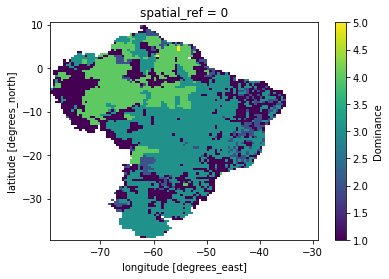

In [175]:
out_grid['Dominance'].plot()

In [176]:
out_grid.to_netcdf('/home/chandra/data/Paper4/Output/Actor_dominance_Mapbiomas.nc')

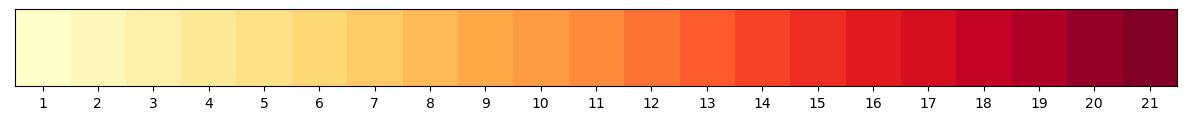

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# create a color map with 21 shades
colors = plt.cm.YlOrRd(np.linspace(0, 1, 21))

# plot the color map as a horizontal bar
fig, ax = plt.subplots(figsize=(15, 1))
ax.imshow([colors], aspect='auto')
ax.set_xticks(np.arange(0, 21))
ax.set_xticklabels(np.arange(1, 22))
ax.set_yticks([])

plt.show()


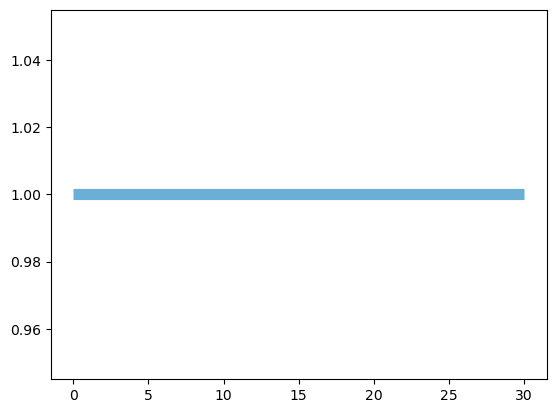

In [8]:
plt.hlines(1, 0, 658, color='#6baed6', lw = 8, zorder = 0)
plt.hlines(2, 0, 495, color='#6baed6', lw = 8, zorder = 0)
plt.hlines(3, 0, 603, color='#6baed6', lw = 8, zorder = 0)

TypeError: object of type 'builtin_function_or_method' has no len()

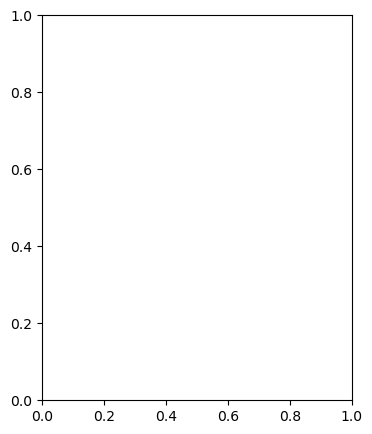

In [14]:
fig = plt.figure(figsize=(4, 5))
ax = fig.add_subplot(111)
axis_break1 = 450
axis_break2 = 9951
x_min = -0.75
x_max = len(data.index)
l = 0.2  # "break" line length
kwargs = dict(color="k", clip_on=False, linewidth=1)
ax.plot((x_min - l, x_min + l), (axis_break2, axis_break2), **kwargs)# top-left
ax.plot((x_max - l, x_max + l), (axis_break2, axis_break2), **kwargs)# top-right
ax2.plot((x_min - l, x_min + l), (axis_break1, axis_break1), **kwargs)# bottom-left
ax2.plot((x_max - l, x_max + l), (axis_break1, axis_break1), **kwargs)# bottom-right